# A — Data, quality and preprocessing
## tl;dr
This notebook recomputes training-only data checks and exploratory plots from the locked UCI legacy CSV.
The training partition contains 27,126 records with 3,173 positive outcomes (11.697%).
The research target is a retrospective simulation of pre-campaign customer screening. It is not a causal marketing-effect estimate.
Exact `pdays` is replaced by prior-contact status; current-campaign fields are excluded. See the computed tables below for observed values.

## Context & Methods
Source: [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank), legacy `bank-full.csv`; CC BY 4.0.
Frozen train / validation / test sizes: 27,126 / 9,042 / 9,043. All target relationships below use train only.
### Key Assumptions
Records have no customer identifier or verified decision-time snapshots. Random splits assess historical record-level generalization.
`unknown` is a category, negative balances are valid observations, and matching profiles are not proof of duplicate customers.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
from src.data import load_partition, audit_data
from src.metrics import binary_metrics
import joblib
EXPERIMENT = ROOT / 'results/experiment'
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})

## Data
### 1. Validate the source and fixed partitions

In [2]:
audit = audit_data()
print('Source shape:', audit['raw_shape'])
print('Partition sizes:', audit['partition_sizes'])
display(pd.Series(audit['train'], name='Training audit').to_frame())
X, y = load_partition('train')
assert X.index.equals(y.index)
from src.preprocessing import HistoryFeatures
duplicate_counts=pd.DataFrame({
    'profile':['16 original inputs','17 original columns including target',
               '11 source fields with exact pdays','11 fields after pdays becomes contact flag'],
    'excess_rows':[audit['train']['exact_16_input_duplicates'],audit['train']['exact_17_column_duplicates'],
                   int(X.duplicated().sum()),int(HistoryFeatures().fit_transform(X).duplicated().sum())]})
display(duplicate_counts)
print('Excess rows = rows minus unique profiles. Matching profiles do not identify customers; no rows removed.')

Source shape: [45211, 17]
Partition sizes: {'train': 27126, 'val': 9042, 'test': 9043}


,Training audit
rows,27126
target_counts,"{'no': 23953, 'yes': 3173}"
positive_rate,0.116973
exact_16_input_duplicates,0
exact_17_column_duplicates,0
11_source_feature_duplicates,575
negative_balance,2280
pdays_never_contacted,22235
pdays_zero_valid_contact,0
never_contacted_but_previous_positive,0


,profile,excess_rows
0,16 original inputs,0
1,17 original columns including target,0
2,11 source fields with exact pdays,575
3,11 fields after pdays becomes contact flag,582


Excess rows = rows minus unique profiles. Matching profiles do not identify customers; no rows removed.


## Results
### 2. Inspect class balance

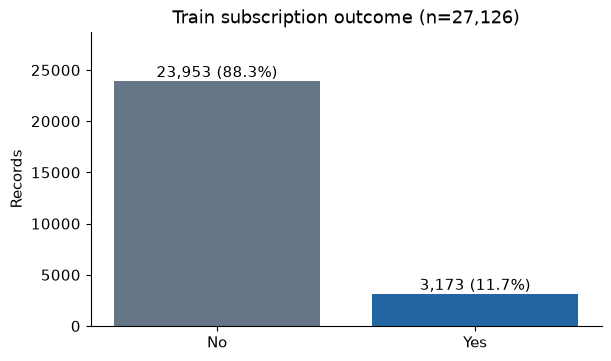

Training positive rate = 11.6973%. Accuracy must be read alongside minority-class metrics.


In [3]:
counts = y.value_counts().reindex([0,1])
fig, ax = plt.subplots(figsize=(6,3.5), layout='constrained')
bars=ax.bar(['No','Yes'], counts, color=['#657786','#2166a0'])
ax.bar_label(bars, labels=[f'{v:,} ({v/len(y):.1%})' for v in counts])
ax.set(title=f'Train subscription outcome (n={len(y):,})',ylabel='Records',ylim=(0,counts.max()*1.2))
plt.show()
print(f'Training positive rate = {y.mean():.4%}. Accuracy must be read alongside minority-class metrics.')

### 3. Examine distributions without clipping observations

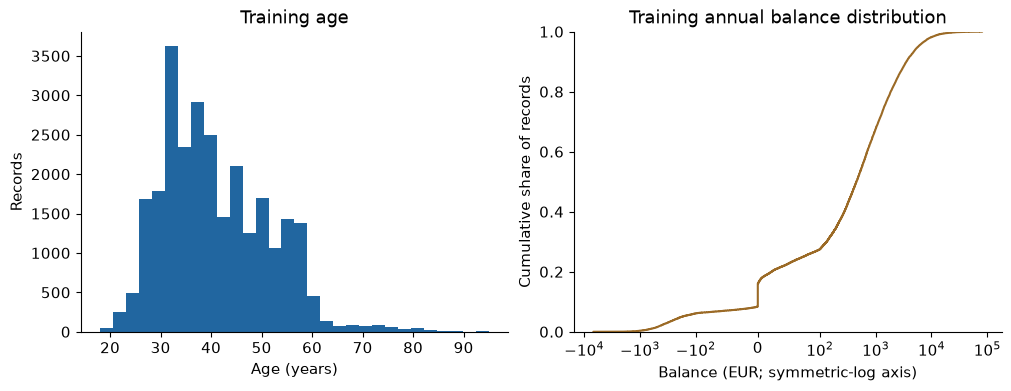

,age,balance,previous
count,27126.00,27126.00,27126.00
mean,40.89,1368.13,0.58
std,10.63,3087.75,1.97
min,18.00,-6847.00,0.00
25%,33.00,73.00,0.00
50%,39.00,454.00,0.00
75%,48.00,1425.75,0.00
max,95.00,81204.00,58.00


In [4]:
fig, axes = plt.subplots(1,2,figsize=(10,3.8),layout='constrained')
axes[0].hist(X.age,bins=30,color='#2166a0'); axes[0].set(title='Training age',xlabel='Age (years)',ylabel='Records')
axes[1].ecdf(X.balance,color='#9b6a26')
axes[1].set_xscale('symlog',linthresh=100)
axes[1].set(title='Training annual balance distribution',xlabel='Balance (EUR; symmetric-log axis)',ylabel='Cumulative share of records')
plt.show()
display(X[['age','balance','previous']].describe().round(2))

### 4. Prior outcomes and observed subscription rates

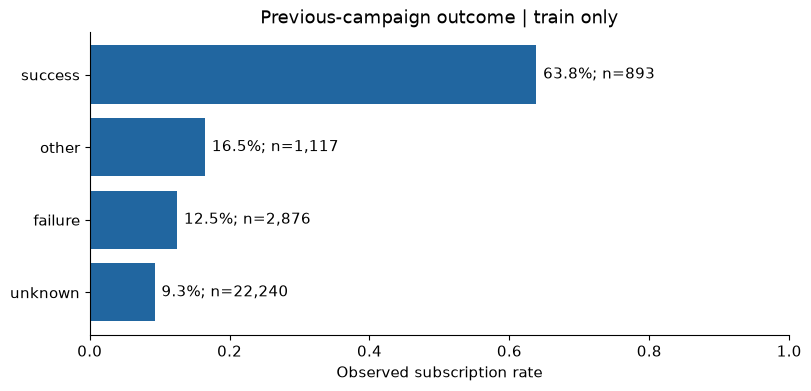

,n,rate
poutcome,,
unknown,22240,0.092626
failure,2876,0.124826
other,1117,0.164727
success,893,0.638298


In [5]:
rates = X.assign(y=y).groupby('poutcome',observed=True).agg(n=('y','size'),rate=('y','mean')).sort_values('rate')
fig, ax=plt.subplots(figsize=(8,3.8),layout='constrained')
bars=ax.barh(rates.index,rates.rate,color='#2166a0')
ax.bar_label(bars,labels=[f'{v.rate:.1%}; n={int(v.n):,}' for v in rates.itertuples()],padding=5)
ax.set(xlim=(0,1),xlabel='Observed subscription rate',title='Previous-campaign outcome | train only')
plt.show()
display(rates)

### 5. Fit a preprocessing example on train only
Literal `unknown` is retained as an ordinary category. Only categories absent from the current fitting
subset become an all-zero one-hot block when encountered later; the record is retained.

In [6]:
from src.preprocessing import build_preprocessor
preprocessor=build_preprocessor(scale_numeric=True)
encoded=preprocessor.fit_transform(X)
names=preprocessor.get_feature_names_out()
assert encoded.shape[0]==len(y) and np.isfinite(encoded).all()
assert not any('pdays' in n or 'duration' in n for n in names)
print('Raw source fields:', X.shape[1], '; transformed inputs:', encoded.shape[1])
display(pd.DataFrame({'encoded_feature':names}))

Raw source fields: 11 ; transformed inputs: 33


,encoded_feature
0,numeric__age
1,numeric__balance
2,numeric__previous
3,numeric__has_previous_contact
4,categorical__job_admin.
5,categorical__job_blue-collar
6,categorical__job_entrepreneur
7,categorical__job_housemaid
8,categorical__job_management
9,categorical__job_retired


## Takeaways
The exact training counts and category summaries above are descriptive associations, not effects of marketing or customer identity evidence.
Use the shared preprocessing constructor inside each CV fit; the illustrative fitted transformer here is never fed into model tuning.
No test prediction or test target-association analysis runs in this notebook. Full CSV tables and report-ready figures are under `results/eda`.
中文交接：字段可得性、数据来源、保留异常值的原因，以及划分限制应保留在报告中。